# TDA fürs Annealing: H0-Balkenmengen und ToMATo gegen die Rate

**Frage.** Taugen topologische Größen als Signal für einen β-Annealer, und was sagen sie, das die Rate nicht schon sagt?
Bisher (gemessen): Zählgrößen wie die Zahl signifikanter ToMATo-Cluster (`tomato_ladder`) oder H0-Komponenten bei 2σ
(`trustworthiness_09` §3) sind früh gesättigt (ab β/d ≈ 10⁻⁴ … 10⁻³ steht dort „1“) und sagen im Bereich vor dem Collapse
nichts mehr. Hier geht es um die **ganze H0-Balkenmenge** (alle Todeszeiten der Komponenten, = Kantenlängen des
minimalen Spannbaums) und um ToMATo-Prominenzen als stetige Größen.

**Erwartung (hergeleitet).** Bei σ ≈ 1,005 konstant (logvar-Klemme) ist R_j ≈ ½ E[μ_j²]. Wird μ gleichmäßig um a
gestaucht, werden alle Abstände in σ-Einheiten und damit alle H0-Todeszeiten um a kleiner, die Rate um a². Also:

  log(Gesamtpersistenz H0) = ½ · log(Rate) + const  (nur unter gleichmäßigem Stauchen).

Die Balkenmenge in σ-Einheiten sollte deshalb eng an der Rate hängen (Steigung ½ im log-log-Bild). Informativ ist die
**Abweichung** davon (Formänderung jenseits des Stauchens) und alles, was skalenfrei ist (Balken auf den Durchmesser
normiert; ToMATo-Prominenzen in log-Dichte, die bei gemeinsamem Stauchen von μ und σ gleich bleiben).

**Daten (kein neues Training):**
- 106er-Studie, TCGA, d = 8, festes β (15 Stufen × Seeds 13/17/23/31), Snapshots alle 50 Epochen bis 750.
- Umschaltläufe `S_T0.750to0.900_k20_e2100_s{17,23,31}` und direkte Läufe `H_T0.900_k20_e2000_s*`
  (`trustworthiness_annealer` §13), Snapshots alle 20 Epochen.

Immer alle 1.001 Validierungspatienten. Rate, AUC und T(z) kommen aus den vorhandenen Auswertungen (`gini_index`,
`analysis_reaction.csv`); AUC nur zur Bewertung.

In [1]:
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.colors import LogNorm
from scipy.stats import spearmanr
from gudhi.clustering.tomato import Tomato

PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "beta_vae_experiments").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from beta_vae_experiments.metrics.complementary.topology_annealing import sigma_unit_distances, h0_death_times

EXPERIMENTS = PROJECT_ROOT / "beta_vae_experiments"
STUDY = EXPERIMENTS / "large_scale_results" / "fixed_beta_106_epochs750_2026_10_27"
ANNEALER_RUNS = EXPERIMENTS / "outputs" / "trustworthiness_annealer" / "runs"
GINI_SUMMARY = EXPERIMENTS / "outputs" / "gini_index" / "gini_summary.parquet"
OUTPUT = EXPERIMENTS / "outputs" / "tda_annealing"
OUTPUT.mkdir(parents=True, exist_ok=True)

SEEDS_SWITCH = (17, 23, 31)
SWITCH_AT, WARMUP = 1100, 100
TOMATO_K, DTM_K, DRAWS, DRAW_SEED = 10, 10, 2, 0
NULL_SAMPLES, NULL_QUANTILE, NULL_EVERY = 10, 0.95, 100
EPS_SIGMA = (1.0, 2.0, 3.0)

run_rows = []
for tag_folder in sorted((STUDY / "runs").glob("tcga_b*_wd0.01")):
    match = re.fullmatch(r"tcga_b([^_]+)_s(\d+)_wd0\.01", tag_folder.name)
    folder = next(path for path in (tag_folder / "run_analysis").iterdir() if path.is_dir())
    run_rows.append(dict(tag=tag_folder.name, source="fixed", beta_over_d=float(match[1]), seed=int(match[2]),
                         folder=folder, epochs=tuple(range(50, 751, 50))))
for seed in SEEDS_SWITCH:
    for source, name, epochs in (("switch", f"S_T0.750to0.900_k20_e2100_s{seed}", 2100),
                                 ("direct", f"H_T0.900_k20_e2000_s{seed}", 2000)):
        run_rows.append(dict(tag=name, source=source, beta_over_d=np.nan, seed=seed, folder=ANNEALER_RUNS / name,
                             epochs=tuple(range(20, epochs + 1, 20))))
runs = pd.DataFrame(run_rows)
assert all((row.folder / "epoch_snapshots").is_dir() for row in runs.itertuples())
display(runs.groupby("source").agg(runs=("tag", "size"), snapshots=("epochs", lambda e: sum(map(len, e)))))

# Rate, Collapse, AUC, T(z) aus den vorhandenen Auswertungen
fixed_metrics = pd.read_parquet(GINI_SUMMARY).query("dataset == 'tcga'")[
    ["tag", "epoch", "rate", "dead_dims", "auc_cancer", "auc_sex_mixed", "trustworthiness_z"]].rename(
    columns={"dead_dims": "dead", "trustworthiness_z": "t_z"})
annealer_metrics = pd.concat([pd.read_csv(ANNEALER_RUNS / name / "analysis_reaction.csv").assign(tag=name)
                              for name in runs[runs.source.ne("fixed")].tag])[
    ["tag", "epoch", "rate", "dead", "auc_cancer", "auc_sex_mixed", "t_z"]]
known = pd.concat([fixed_metrics, annealer_metrics], ignore_index=True).astype({"epoch": int})

,runs,snapshots
source,,
direct,3,300
fixed,60,900
switch,3,315


## 1. Topologische Größen pro Snapshot

**H0-Balkenmenge** in drei Räumen (Todeszeiten = MST-Kantenlängen, `h0_death_times`):

| Raum | Abstand | sieht Stauchen? |
|---|---|---|
| σ-Einheiten auf μ | √(Σ_k (μ_ik − μ_jk)² / mittlere Varianz), Bhattacharyya-Mittelterm (`sigma_unit_distances`) | ja |
| z (gespeicherte Ziehung) | euklidisch auf z = μ + σ·ε | ja, über das Rauschen |
| μ, Durchmesser-normiert | euklidisch auf μ / max. Abstand | **nein** (nur Form) |

Pro Raum: Gesamtpersistenz Σ d, Median, 90-%-Quantil, längster Balken, Persistenz-Entropie der normierten Balken
(−Σ p log p mit p = d / Σ d; skalenfrei); in σ-Einheiten zusätzlich die Komponenten bei 1σ / 2σ / 3σ.

**ToMATo** (wie `tomato_ladder`: log-DTM, k = 10, gespeichertes z + 2 Ziehungen = 3.003 Punkte): größte und zweitgrößte
Prominenz, Summe der 10 größten. An jeder 100. Epoche (106er-Studie: nur Epoche 750) zusätzlich die Nullschwelle
(95-%-Quantil der größten Prominenz unter einer Gauß-Wolke mit gleicher Kovarianz, 10 Stichproben), daraus signifikante
Cluster und die Marge log(p₁ / t₉₅).

In [2]:
def bar_statistics(deaths, prefix):
    deaths = np.asarray(deaths, dtype=np.float64)
    total = deaths.sum()
    share = deaths / total if total > 0 else np.full(len(deaths), np.nan)
    with np.errstate(divide="ignore", invalid="ignore"):
        entropy = float(-(share[share > 0] * np.log(share[share > 0])).sum()) if total > 0 else np.nan
    return {f"{prefix}_total": float(total), f"{prefix}_median": float(np.median(deaths)),
            f"{prefix}_q90": float(np.quantile(deaths, .9)), f"{prefix}_max": float(deaths.max()),
            f"{prefix}_entropy": entropy}


def euclidean(points):
    squared = (points ** 2).sum(1)
    distances = np.sqrt(np.maximum(squared[:, None] + squared[None] - 2 * points @ points.T, 0))
    np.fill_diagonal(distances, 0)
    return (distances + distances.T) / 2


def draw_points(mu, logvar, z, draws=DRAWS, seed=DRAW_SEED):
    rng = np.random.default_rng(seed)
    sigma = np.exp(logvar / 2)
    return np.concatenate([z] + [mu + sigma * rng.standard_normal(mu.shape) for _ in range(draws)])


def prominences(points):
    model = Tomato(density_type="logDTM", k=TOMATO_K, k_DTM=DTM_K).fit(points)
    weights = model.weights_
    values = [b - d for b, d in model.diagram_]
    peaks = np.sort(np.asarray(model.max_weight_per_cc_))[::-1]
    values += [p - weights.min() for p in peaks[1:]]  # weitere Zusammenhangskomponenten
    return np.sort(np.asarray(values))[::-1] if values else np.zeros(1)


def null_threshold(mu, logvar, seed=1):
    rng = np.random.default_rng(seed)
    mean, cov = mu.mean(0), np.cov(mu, rowvar=False)
    largest = []
    for index in range(NULL_SAMPLES):
        fake = rng.multivariate_normal(mean, cov, size=len(mu))
        sigma = np.exp(logvar / 2)
        points = np.concatenate([fake + sigma * np.random.default_rng(seed + index + j).standard_normal(fake.shape)
                                 for j in range(DRAWS + 1)])
        largest.append(prominences(points)[0])
    return float(np.quantile(largest, NULL_QUANTILE))


def tda_measures(mu, logvar, z, with_null):
    row = {}
    sigma_distances = sigma_unit_distances(mu, logvar)
    deaths = h0_death_times(sigma_distances)
    row |= bar_statistics(deaths, "h0_sigma")
    row |= {f"h0_sigma_components_{eps:g}": int(1 + np.sum(deaths >= eps)) for eps in EPS_SIGMA}
    row |= bar_statistics(h0_death_times(euclidean(z)), "h0_z")
    mu_distances = euclidean(mu)
    diameter = mu_distances.max()
    row |= bar_statistics(h0_death_times(mu_distances / diameter) if diameter > 0 else np.zeros(len(mu) - 1), "h0_shape")
    values = prominences(draw_points(mu, logvar, z))
    row |= dict(tomato_p1=float(values[0]), tomato_p2=float(values[1]) if len(values) > 1 else 0.0,
                tomato_top10=float(values[:10].sum()))
    if with_null:
        threshold = null_threshold(mu, logvar)
        row |= dict(tomato_threshold=threshold, tomato_clusters=int(1 + np.sum(values > threshold)),
                    tomato_margin=float(np.log(values[0] / threshold)) if values[0] > 0 else np.nan)
    return row


# Test der Herleitung: μ gleichmäßig stauchen (σ fest) → σ-Balken × a, Form-Balken unverändert, Rate × a².
rng = np.random.default_rng(0)
test_mu, test_logvar = np.abs(rng.normal(0, 3, (300, 8))), np.full((300, 8), 0.01)
full, half = (bar_statistics(h0_death_times(sigma_unit_distances(a * test_mu, test_logvar)), "s") for a in (1, .5))
shape_full, shape_half = (bar_statistics(h0_death_times(euclidean(a * test_mu) / euclidean(a * test_mu).max()), "f") for a in (1, .5))
assert np.isclose(half["s_total"], .5 * full["s_total"]) and np.isclose(half["s_entropy"], full["s_entropy"])
assert np.isclose(shape_half["f_total"], shape_full["f_total"])
print("Herleitung geprüft: Stauchen um ½ halbiert die σ-Balken, Entropie und Form-Balken bleiben gleich.")

Herleitung geprüft: Stauchen um ½ halbiert die σ-Balken, Entropie und Form-Balken bleiben gleich.


In [3]:
cache = OUTPUT / "tda_snapshots.parquet"
tda = pd.read_parquet(cache) if cache.exists() else pd.DataFrame(columns=["tag", "epoch"])
done = set(zip(tda.tag, tda.epoch.astype(int)))
new_rows = []
for run in runs.itertuples():
    for epoch in run.epochs:
        if (run.tag, epoch) in done:
            continue
        path = run.folder / "epoch_snapshots" / f"epoch_{epoch:05d}_valid.npz"
        if not path.exists():
            continue
        with np.load(path) as saved:
            order = np.argsort(saved["sample_ids"].astype(str))
            mu, logvar, z = (saved[key][order].astype(np.float64) for key in ("mu", "logvar", "z"))
        with_null = epoch == 750 if run.source == "fixed" else epoch % NULL_EVERY == 0
        new_rows.append(dict(tag=run.tag, source=run.source, seed=run.seed, beta_over_d=run.beta_over_d, epoch=epoch)
                        | tda_measures(mu, logvar, z, with_null))
    if new_rows:  # nach jedem Lauf sichern
        tda = pd.concat([tda, pd.DataFrame(new_rows)], ignore_index=True)
        tda.to_parquet(cache)
        new_rows = []
tda = tda.astype({"epoch": int, "seed": int}).merge(known, on=["tag", "epoch"], how="left")
print(f"{len(tda)} Snapshots, {tda.tag.nunique()} Läufe")

1515 Snapshots, 66 Läufe


## 2. H0-Balkenmengen

Links: 106er-Studie, Seed 17, Epoche 750, ausgewählte β/d. Rechts: Umschaltlauf Seed 17 an markanten Epochen (Ende
Warm-up, Collapse, Ende Phase 0,75, kurz nach dem Umschalten, Ende). Jeder Balken eine H0-Komponente, Länge = Todeszeit in
σ-Einheiten, sortiert; die Achse ist logarithmisch. Gestrichelt: 1σ, 2σ, 3σ.

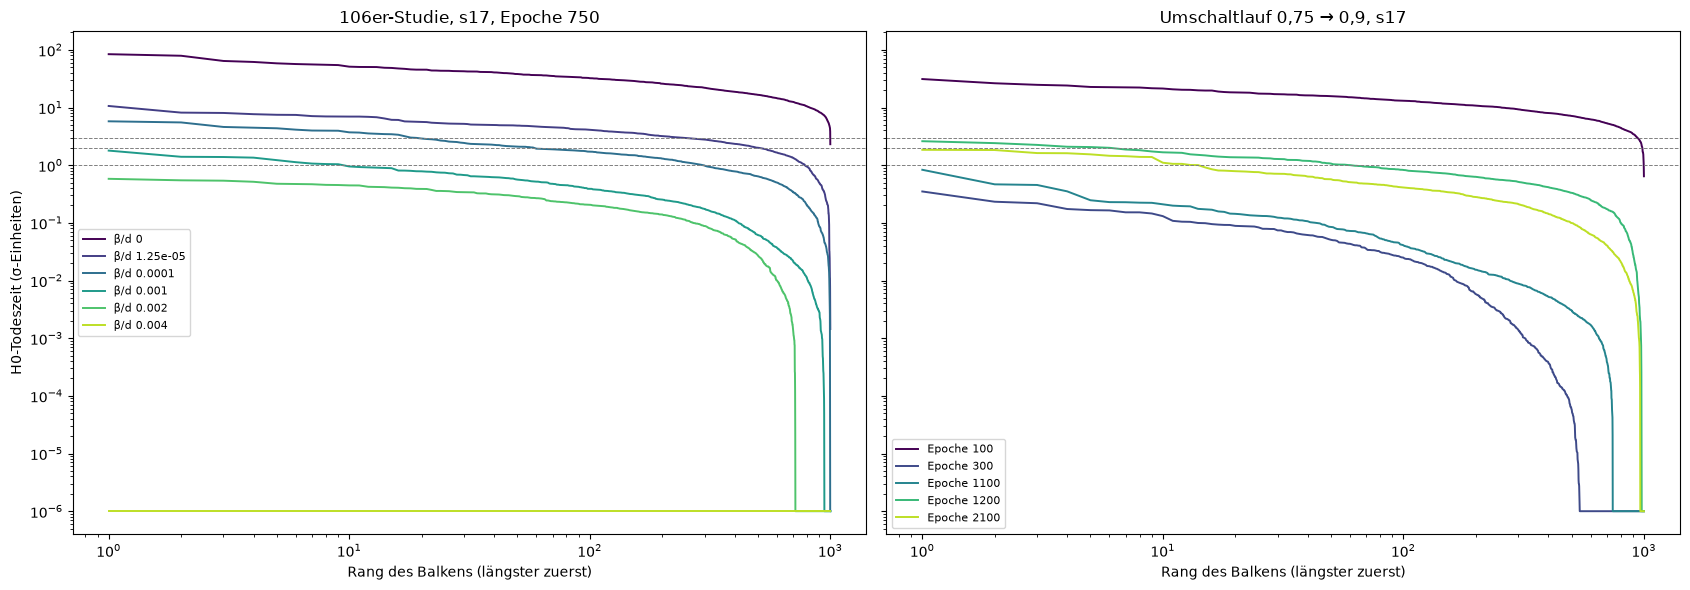

In [4]:
def load_valid(folder, epoch):
    with np.load(folder / "epoch_snapshots" / f"epoch_{epoch:05d}_valid.npz") as saved:
        return saved["mu"].astype(np.float64), saved["logvar"].astype(np.float64)


fig, axes = plt.subplots(1, 2, figsize=(17, 6), sharey=True)
panels = [(axes[0], [(f"β/d {b:g}", runs[(runs.source == "fixed") & (runs.seed == 17) & np.isclose(runs.beta_over_d, b)].folder.iloc[0], 750)
                     for b in (0.0, 1.25e-5, 1e-4, 1e-3, 2e-3, 4e-3)], "106er-Studie, s17, Epoche 750"),
          (axes[1], [(f"Epoche {e}", ANNEALER_RUNS / "S_T0.750to0.900_k20_e2100_s17", e) for e in (100, 300, 1100, 1200, 2100)],
           "Umschaltlauf 0,75 → 0,9, s17")]
for ax, items, title in panels:
    colors = plt.cm.viridis(np.linspace(0, .9, len(items)))
    for (label, folder, epoch), color in zip(items, colors):
        deaths = np.sort(h0_death_times(sigma_unit_distances(*load_valid(folder, epoch))))[::-1]
        ax.plot(np.arange(1, len(deaths) + 1), np.maximum(deaths, 1e-6), color=color, lw=1.4, label=label)
    for eps in EPS_SIGMA:
        ax.axhline(eps, color="grey", ls="--", lw=.7)
    ax.set(xscale="log", yscale="log", xlabel="Rang des Balkens (längster zuerst)", title=title)
    ax.legend(fontsize=8)
axes[0].set_ylabel("H0-Todeszeit (σ-Einheiten)")
fig.tight_layout()
fig.savefig(OUTPUT / "h0_barcodes.png", dpi=150)
plt.show()

## 3. TDA gegen Rate

Jeder Punkt ein Snapshot (106er-Studie: Farbe = β/d; Umschalt- und direkte Läufe grau bzw. schwarz). Im ersten Bild ist
die Gerade mit Steigung ½ eingezeichnet, die bei reinem Stauchen gelten müsste (Achsenabschnitt aus dem Median).
Vollständig kollabierte Snapshots (Rate am Boden, alle μ = 0) sind ausgelassen; dort sind alle Balken 0.

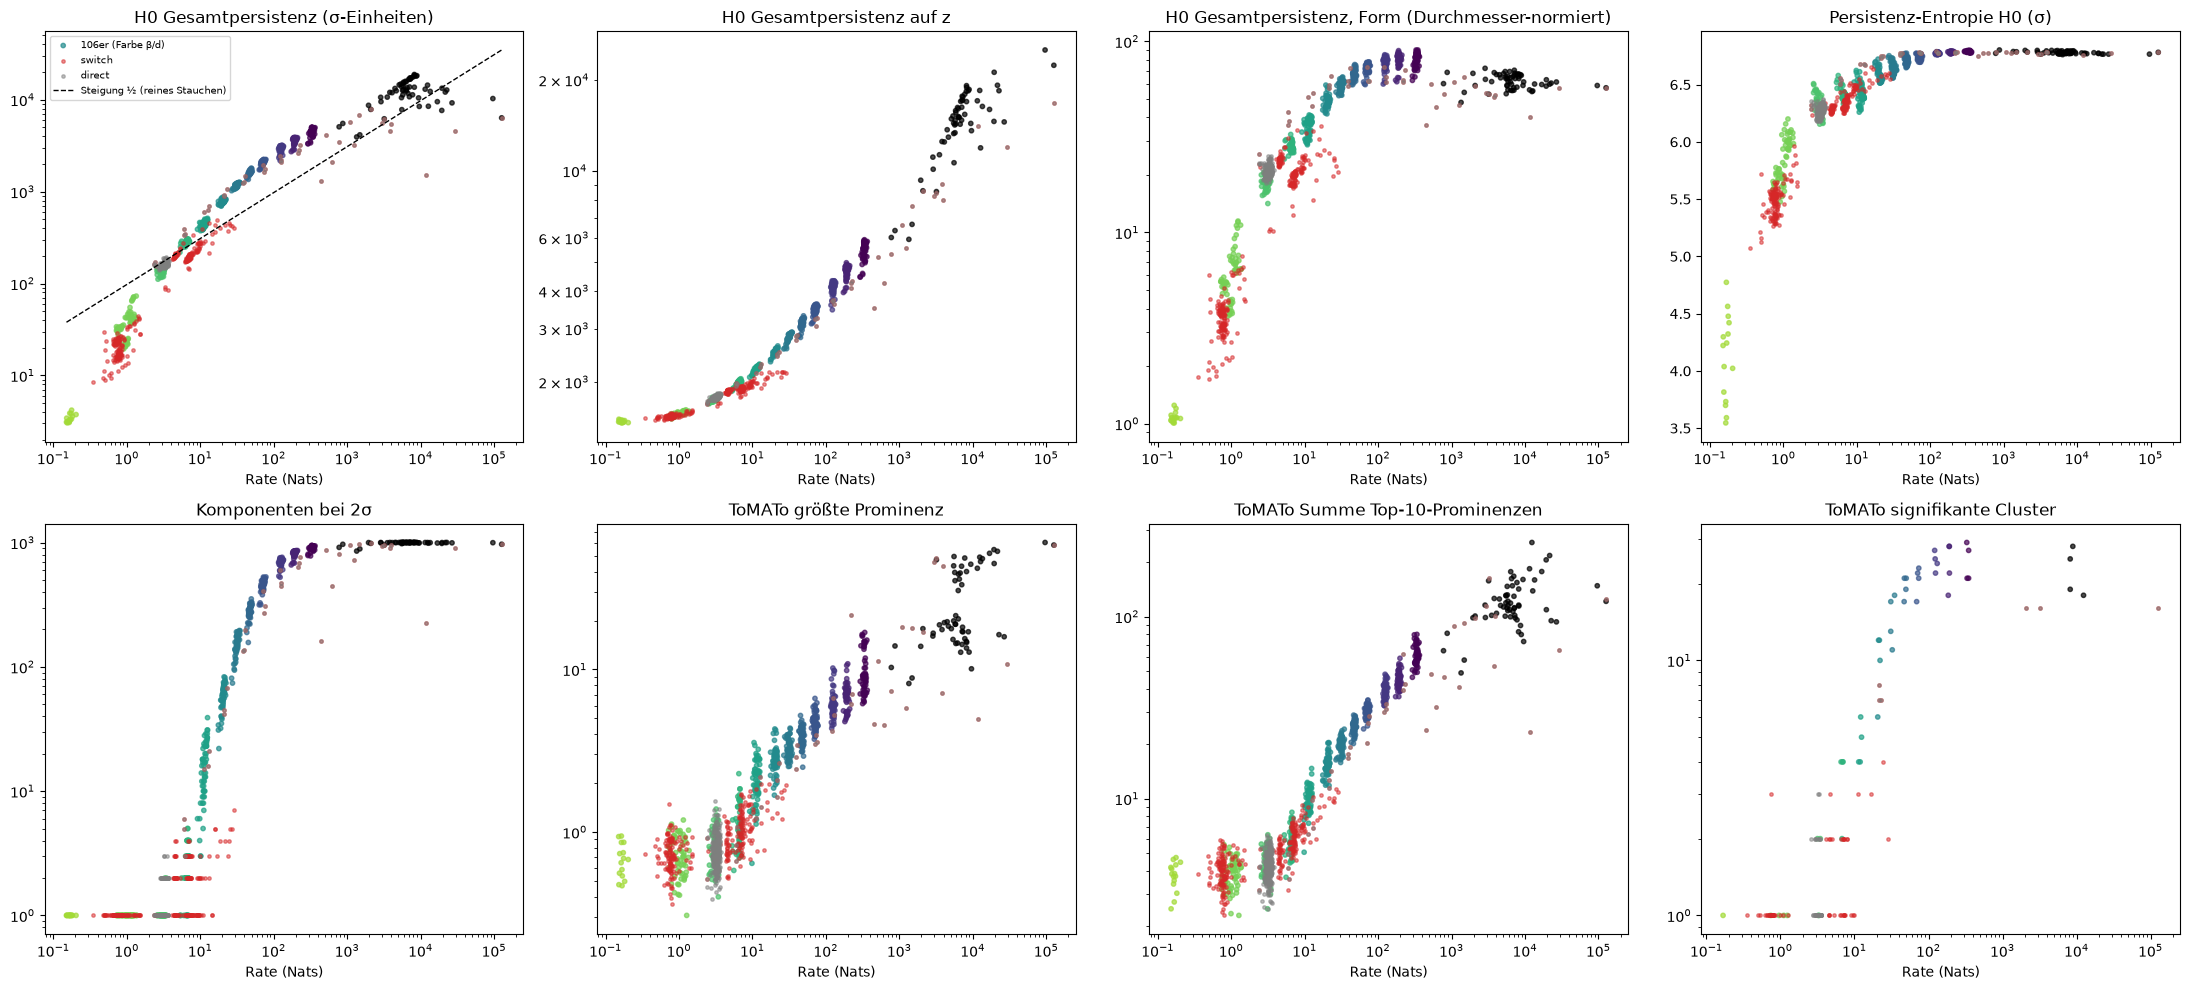

In [5]:
TDA_PANELS = [("h0_sigma_total", "H0 Gesamtpersistenz (σ-Einheiten)", True), ("h0_z_total", "H0 Gesamtpersistenz auf z", True),
              ("h0_shape_total", "H0 Gesamtpersistenz, Form (Durchmesser-normiert)", True),
              ("h0_sigma_entropy", "Persistenz-Entropie H0 (σ)", False), ("h0_sigma_components_2", "Komponenten bei 2σ", True),
              ("tomato_p1", "ToMATo größte Prominenz", True), ("tomato_top10", "ToMATo Summe Top-10-Prominenzen", True),
              ("tomato_clusters", "ToMATo signifikante Cluster", True)]
alive = tda[tda.rate > 1e-2].copy()
beta_norm = LogNorm(vmin=1e-6, vmax=1.5e-2)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, (column, title, log_y) in zip(axes.ravel(), TDA_PANELS):
    fixed = alive[alive.source.eq("fixed") & alive[column].notna()]
    ax.scatter(fixed.rate, fixed[column], c=[plt.cm.viridis(beta_norm(max(b, 1e-6))) if b > 0 else "k" for b in fixed.beta_over_d],
               s=10, alpha=.7, label="106er (Farbe β/d)")
    for source, color in (("switch", "tab:red"), ("direct", "tab:grey")):
        part = alive[alive.source.eq(source) & alive[column].notna()]
        ax.scatter(part.rate, part[column], color=color, s=6, alpha=.5, label=source)
    if column == "h0_sigma_total":
        x = np.geomspace(alive.rate.min(), alive.rate.max(), 50)
        offset = np.median(np.log(alive[column]) - .5 * np.log(alive.rate))
        ax.plot(x, np.exp(offset) * x ** .5, "k--", lw=1, label="Steigung ½ (reines Stauchen)")
    ax.set(xscale="log", yscale="log" if log_y else "linear", xlabel="Rate (Nats)", title=title)
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(OUTPUT / "tda_vs_rate.png", dpi=150)
plt.show()

## 4. Wie viel davon ist nur Rate?

Pro Größe, über alle nicht vollständig kollabierten Snapshots:

- **Spearman mit log Rate** (Kopplung an die Rate),
- **partielle Spearman-Korrelation mit der Krebs-AUC bei festgehaltener log Rate** (Ränge auf den Rang der Rate
  regressiert, Korrelation der Residuen): Information über die Rate hinaus. Nur Bewertung, Labels steuern nichts,
- **Steigung im log-log gegen die Rate** (½ = reines Stauchen) und R²,
- **Sättigung:** Anteil der 106er-Snapshots zwischen β/d 10⁻³ und 2·10⁻³ (direkt vor dem Collapse), in denen sich die
  Größe gegenüber 10⁻³ um weniger als 5 % ändert,
- **Rauschen:** Streuung über die Epochen 500–750 desselben Laufs (106er, festes β) relativ zum Sprung zwischen
  benachbarten β-Stufen (Median).

Snapshots desselben Laufs sind nicht unabhängig; die Korrelationen sind beschreibend, keine Tests.

In [6]:
def partial_spearman(x, y, control):
    ranks = [pd.Series(values).rank().to_numpy() for values in (x, y, control)]
    design = np.column_stack([np.ones(len(x)), ranks[2]])
    residual = [r - design @ np.linalg.lstsq(design, r, rcond=None)[0] for r in ranks[:2]]
    return float(np.corrcoef(*residual)[0, 1])


table_rows = []
fixed_final = alive[alive.source.eq("fixed")]
for column, title, _ in TDA_PANELS:
    part = alive.dropna(subset=[column, "rate", "auc_cancer"])
    positive = part[part[column] > 0]
    slope, intercept = np.polyfit(np.log(positive.rate), np.log(positive[column]), 1) if len(positive) > 2 else (np.nan, np.nan)
    r2 = np.corrcoef(np.log(positive.rate), np.log(positive[column]))[0, 1] ** 2 if len(positive) > 2 else np.nan
    late = fixed_final[fixed_final.epoch.between(500, 750)]
    per_level = late.groupby(["beta_over_d", "seed"])[column]
    noise = per_level.std().groupby("beta_over_d").median()
    level_means = late.groupby("beta_over_d")[column].mean()
    step = level_means.diff().abs().median()
    edge = fixed_final[fixed_final.epoch.eq(750) & fixed_final.beta_over_d.isin([1e-3, 2e-3])].pivot_table(
        index="seed", columns="beta_over_d", values=column)
    saturated = float(((edge[2e-3] - edge[1e-3]).abs() / edge[1e-3].abs() < .05).mean()) if edge.shape[1] == 2 else np.nan
    table_rows.append({"Größe": title, "Spearman log Rate": spearmanr(part[column], np.log(part.rate))[0],
                       "partiell AUC | Rate": partial_spearman(part[column], part.auc_cancer, np.log(part.rate)),
                       "Steigung log-log": slope, "R² log-log": r2, "gesättigt 10⁻³→2·10⁻³": saturated,
                       "Rauschen / Sprung": noise.median() / step if step else np.nan})
summary = pd.DataFrame(table_rows).set_index("Größe")
summary.to_csv(OUTPUT / "tda_vs_rate_summary.csv")
display(summary.style.format(precision=2))

,Spearman log Rate,partiell AUC | Rate,Steigung log-log,R² log-log,gesättigt 10⁻³→2·10⁻³,Rauschen / Sprung
Größe,,,,,,
H0 Gesamtpersistenz (σ-Einheiten),0.99,0.55,0.72,0.89,0.00,0.05
H0 Gesamtpersistenz auf z,0.99,0.54,0.23,0.94,0.00,0.08
"H0 Gesamtpersistenz, Form (Durchmesser-normiert)",0.92,0.68,0.34,0.64,0.00,0.14
Persistenz-Entropie H0 (σ),0.96,0.23,0.02,0.54,0.25,0.20
Komponenten bei 2σ,0.93,0.30,1.06,0.80,1.00,0.06
ToMATo größte Prominenz,0.90,0.07,0.44,0.88,0.25,0.53
ToMATo Summe Top-10-Prominenzen,0.93,0.10,0.44,0.90,0.00,0.28
ToMATo signifikante Cluster,0.80,0.21,0.42,0.68,0.50,nan


## 5. Verlauf im Umschaltversuch

Normiert auf das Ende des Warm-ups (Epoche 100 = 1), Median über die drei Seeds; Rate zum Vergleich. Gestrichelt: das
Umschalten bei Epoche 1.100. So sieht man, ob eine TDA-Größe vor dem Collapse (Epoche ≈ 280) anschlägt, mit ihm springt
oder ihm nachläuft.

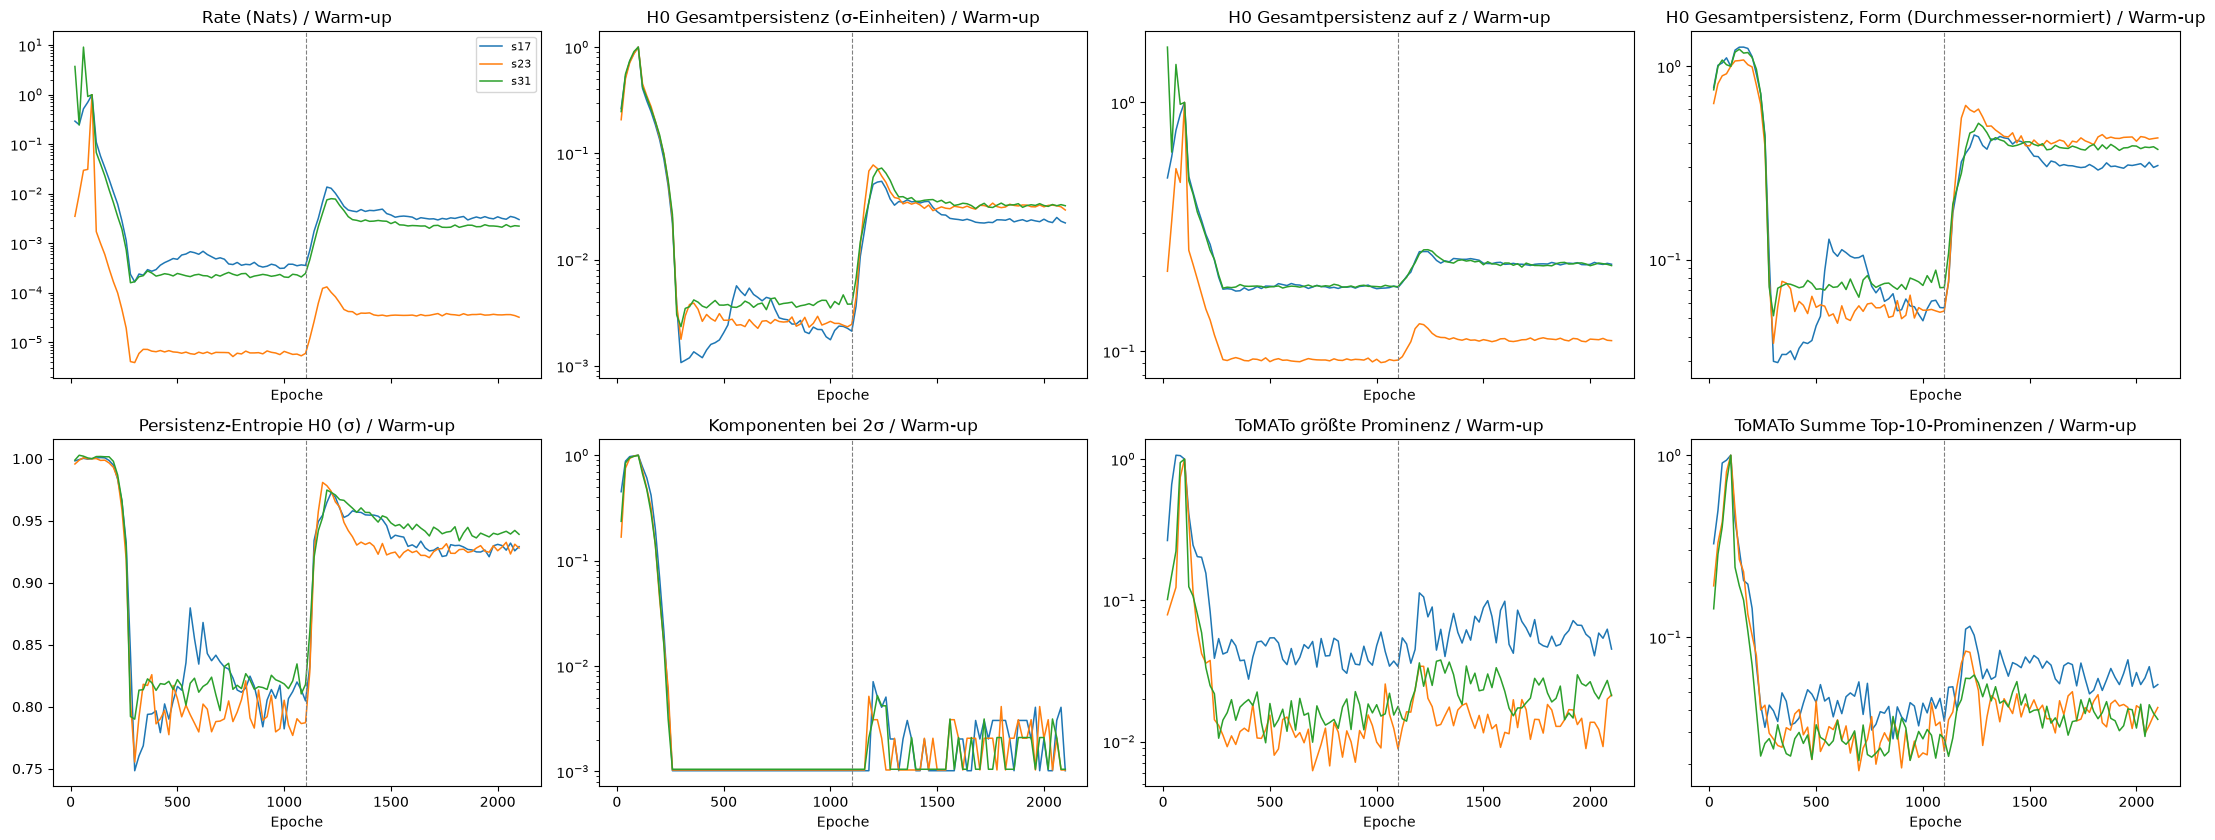

In [7]:
switch = tda[tda.source.eq("switch")]
fig, axes = plt.subplots(2, 4, figsize=(22, 8.5), sharex=True)
for ax, (column, title, log_y) in zip(axes.ravel(), [("rate", "Rate (Nats)", True)] + TDA_PANELS[:7]):
    for seed, part in switch.groupby("seed"):
        part = part.sort_values("epoch").dropna(subset=[column])
        base = part.set_index("epoch")[column].get(WARMUP, np.nan)
        ax.plot(part.epoch, part[column] / base if base else part[column], lw=1.1, label=f"s{seed}")
    ax.axvline(SWITCH_AT, color="grey", ls="--", lw=.8)
    ax.set(title=f"{title} / Warm-up", yscale="log" if log_y else "linear", xlabel="Epoche")
axes[0, 0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(OUTPUT / "tda_switch.png", dpi=150)
plt.show()

## 6. Befunde (gemessen, 1.515 Snapshots, 66 Läufe; Tabelle in Abschnitt 4)

1. **Alle TDA-Größen hängen eng an der Rate:** Spearman mit log Rate 0,80 (ToMATo-Clusterzahl) bis 0,99 (H0 auf z).
   Die Balkenmengen sind also im Wesentlichen ein anderes Maß für die Rate.
2. **Steigung nicht ½:** H0-Gesamtpersistenz in σ-Einheiten gegen Rate hat im log-log die Steigung 0,72 (alle Snapshots;
   0,87 nur 106er mit β > 0) statt ½. Unterhalb von ≈ 3 Nats fällt sie deutlich steiler als bei reinem Stauchen: Patienten
   rücken auf identische Punkte (μ = 0 in denselben Dimensionen), MST-Kanten verschwinden schneller, als die Rate sinkt.
3. **Gesättigt (nicht brauchbar vor der Kante):** Komponenten bei 2σ (zwischen β/d 10⁻³ und 2·10⁻³ in allen Seeds
   unverändert = 1) und ToMATo-Clusterzahl (ab ≈ 10 Nats = 1). **Nicht gesättigt:** H0-Gesamtpersistenz in allen drei
   Räumen und die Persistenz-Entropie ändern sich dort noch.
4. **Die skalenfreie Form-Persistenz** (Durchmesser-normiert, sieht kein Stauchen) ist bei hoher Rate flach (≈ 60–80) und
   fällt unterhalb von ≈ 10 Nats um zwei Größenordnungen. Sie misst damit das Zusammenfallen der Patienten auf die Klemme,
   nicht das Stauchen.
5. **Ruhig:** Rauschen innerhalb eines Laufs (Epoche 500–750, festes β) 5–14 % des Sprungs zwischen β-Stufen bei den
   H0-Größen, 28–53 % bei ToMATo-Prominenzen.
6. **Information über die Rate hinaus — nur während des Trainings, nicht im Gleichgewicht:** Über alle Snapshots ist die
   partielle Korrelation mit der Krebs-AUC bei festgehaltener Rate 0,55 (σ-H0), 0,54 (z-H0), 0,68 (Form-H0); ToMATo
   0,07–0,21. Nur auf den eingeschwungenen 106er-Läufen (Epoche 750, β > 0, n = 45) verschwindet sie (−0,20 … +0,09).
   Der Zusatz kommt also aus Übergängen (Training, Umschalten), in denen AUC und Rate nicht im Gleichschritt laufen.
7. **Zurückgeholtes gegen nie kollabiertes Modell bei ähnlicher Rate** (Ende Umschaltlauf, Rate 6,7, 3 tote Dims, gegen
   festes β mit Rate ≈ 5, keine tote Dim): σ-H0 199 gegen 212, Form-H0 20,1 gegen 23,8, also trotz höherer Rate etwas
   kleiner. Die H0-Balken unterscheiden die beiden Zustände in die erwartete Richtung, aber nur um 6–15 %; schwacher Befund.

**Folgerung für den Annealer (Vermutung, ungeprüft):** Als Collapse-Wächter bringt H0 gegenüber der Rate pro Dimension
nichts Neues. Brauchbar wären die Form-Persistenz und die Entropie als ruhige, nicht gesättigte Begleitsignale für Ziel 2
(Struktur jenseits der Rate) und als Diagnose von Übergängen; ToMATo bleibt Diagnose.